# Clase 5 — Evaluación de modelos de clasificación

**Objetivo:** comprender e implementar las métricas de evaluación vistas en la cursada, usando Titanic.

Este notebook es una guía de práctica, no una resolución.


## 0. Recuperar el modelo anterior

Primero vamos a reutilizar el procedimiento de preparación y entrenamiento que construiste en `01_modelado_titanic.ipynb`.


In [144]:
import pandas as pd
import seaborn as sns

df = sns.load_dataset('titanic')

In [145]:
X = df[['sex', 'age', 'class']]
y = df['survived']

In [146]:
X["sex"] = X["sex"].map({
    "male": 0,
    "female": 1
})

X["class"] = X["class"].map({
    "First": 1,
    "Second": 2,
    "Third": 3
}).astype(int)

In [147]:
import sklearn as skl
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [148]:
X_train["age"] = X_train["age"].fillna(X_train["age"].median())
X_test["age"] = X_test["age"].fillna(X_train["age"].median())

In [149]:
from sklearn.tree import DecisionTreeClassifier

modelo = DecisionTreeClassifier(max_depth=3)

modelo.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

## 1. Accuracy

**Fuente:** diapositivas de Clase 5, sección Accuracy.

- ¿Qué mide el accuracy?
- ¿Cuál fue el accuracy de tu árbol con Titanic?
- ¿Cuántos aciertos representa sobre el conjunto de prueba?


In [150]:
from sklearn.metrics import accuracy_score

y_pred = modelo.predict(X_test)

print(y_pred[:10])

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

y_test == y_pred

print(sum(y_test == y_pred)/y_test.size)



[0 0 0 0 1 1 1 0 0 0]
Accuracy: 0.7653631284916201
0.7653631284916201


## 2. Accuracy Paradox

**Fuente:** diapositivas de Clase 5, sección Accuracy Paradox.

Investigar la distribución de clases en `y_test`. Comparar el accuracy del árbol con la proporción de la clase mayoritaria.

**Para pensar:** ¿un clasificador que responde siempre la clase mayoritaria podría alcanzar un accuracy aparentemente alto?


In [151]:
y_test.value_counts()


survived
0    110
1     69
Name: count, dtype: int64

## 3. Matriz de confusión

**Fuente:** diapositivas de Clase 5, sección Confusion Matrix.

Interpretar los errores de tipo FP y FN en el problema Titanic.


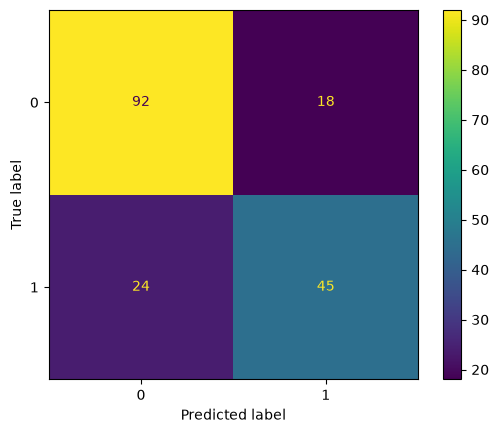

In [152]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

### Otra forma de hacerlo (Como lo hacen en clase)

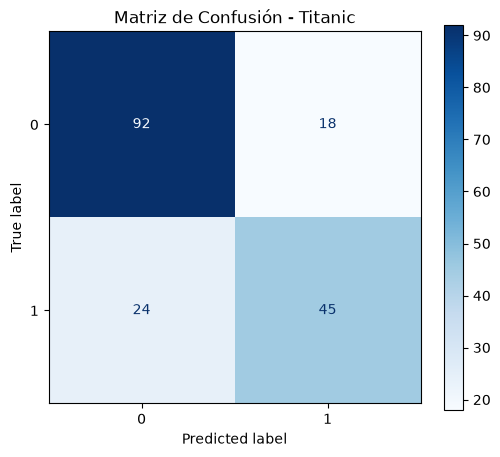

In [153]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_estimator(
    modelo, X_test, y_test, cmap="Blues", ax=ax
)

plt.title("Matriz de Confusión - Titanic")
plt.show()

## 4. Precision y recall

**Fuente:** diapositivas de Clase 5, sección Precision & Recall.

¿Qué mide cada una? ¿Cómo cambia la interpretación si tomamos como clase positiva `survived = 1`?


In [154]:
from sklearn.metrics import precision_score, recall_score

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)


print("Precision:", precision)
print("Recall:", recall)

Precision: 0.7142857142857143
Recall: 0.6521739130434783


## 5. F1-score

Explicar la relación entre precision y recall y luego calcular F1, una vez revisada la métrica en la práctica.


In [155]:
from sklearn.metrics import f1_score

f1 = f1_score(y_test, y_pred)

print("F1-score:", f1)

F1-score: 0.6818181818181818


### Reporte de todas las metricas importantes

In [156]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.79      0.84      0.81       110
           1       0.71      0.65      0.68        69

    accuracy                           0.77       179
   macro avg       0.75      0.74      0.75       179
weighted avg       0.76      0.77      0.76       179



## 6. Decision Threshold

In [157]:
y_prob = modelo.predict_proba(X_test)

print(y_prob[:10])

[[0.88951841 0.11048159]
 [0.88951841 0.11048159]
 [0.88951841 0.11048159]
 [0.88951841 0.11048159]
 [0.45714286 0.54285714]
 [0.45714286 0.54285714]
 [0.04511278 0.95488722]
 [0.63736264 0.36263736]
 [0.63736264 0.36263736]
 [0.88951841 0.11048159]]


In [158]:
y_prob_positiva = y_prob[:, 1]

print(y_prob_positiva[:10])

[0.11048159 0.11048159 0.11048159 0.11048159 0.54285714 0.54285714
 0.95488722 0.36263736 0.36263736 0.11048159]


### Pruebo que pasa si bajo el umbral de decision

In [159]:
threshold = 0.30

y_pred_30 = (y_prob_positiva >= threshold).astype(int)

print(y_pred_30[:10])

[0 0 0 0 1 1 1 1 1 0]


### Vemos que pasa con las metricas que establecimos antes

In [160]:
print("Precision:", precision_score(y_test, y_pred_30))
print("Recall:", recall_score(y_test, y_pred_30))
print("F1-score:", f1_score(y_test, y_pred_30))

Precision: 0.6021505376344086
Recall: 0.8115942028985508
F1-score: 0.691358024691358


### Chequeamos que paso en la matriz de confusion

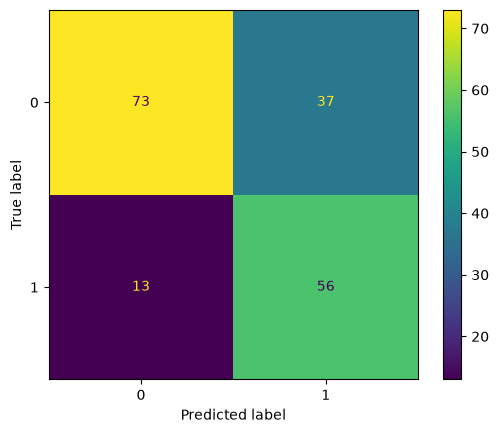

In [161]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_30)

### Aumentamos el decision Threshold a un 70% para ver que pasa (aumenta precision y disminuye recall)

In [162]:
threshold = 0.70

y_pred_70 =  (y_prob_positiva >= threshold).astype(int)

print("Precision:", precision_score(y_test, y_pred_70))
print("Recall:", recall_score(y_test, y_pred_70))
print("F1-score:", f1_score(y_test, y_pred_70))

Precision: 0.9393939393939394
Recall: 0.4492753623188406
F1-score: 0.6078431372549019


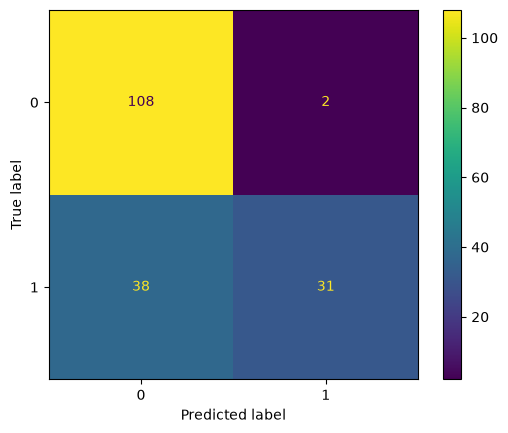

In [163]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_70)

In [164]:
print(classification_report(y_test, y_pred_70))

              precision    recall  f1-score   support

           0       0.74      0.98      0.84       110
           1       0.94      0.45      0.61        69

    accuracy                           0.78       179
   macro avg       0.84      0.72      0.73       179
weighted avg       0.82      0.78      0.75       179



### Seleccion mas sistematica de umbrales

In [165]:
umbrales = [0.1, 0.3, 0.5, 0.7, 0.9]
precisions = []
recalls = []
f1s =[]

for umbral in umbrales:
    predicciones = (y_prob_positiva >= umbral).astype(int)

    precision = precision_score(y_test, predicciones, zero_division=0)
    recall = recall_score(y_test, predicciones)
    f1 = f1_score(y_test, predicciones)

    precisions.append(precision)
    recalls.append(recall)
    f1s.append(f1)

    print(f"Umbral: {umbral}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
    print(f"F1-score: {f1:.2f}")
    print("--------------------")

Umbral: 0.1
Precision: 0.39
Recall: 1.00
F1-score: 0.56
--------------------
Umbral: 0.3
Precision: 0.60
Recall: 0.81
F1-score: 0.69
--------------------
Umbral: 0.5
Precision: 0.71
Recall: 0.65
F1-score: 0.68
--------------------
Umbral: 0.7
Precision: 0.94
Recall: 0.45
F1-score: 0.61
--------------------
Umbral: 0.9
Precision: 0.93
Recall: 0.41
F1-score: 0.57
--------------------


### Imprimimos como varian las metricas

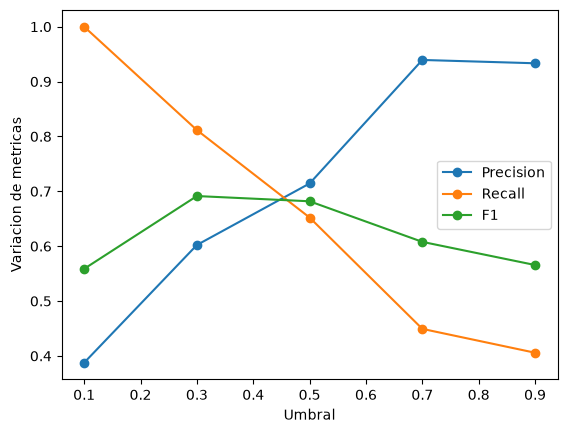

In [166]:
import matplotlib.pyplot as plt

plt.plot(umbrales, precisions, label="Precision", marker="o")
plt.plot(umbrales, recalls, label="Recall", marker="o")
plt.plot(umbrales, f1s, label="F1", marker="o")
plt.xlabel("Umbral")
plt.ylabel("Variacion de metricas")
plt.legend()
plt.show()

### Calculamos la curva ROC

In [167]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob_positiva)

print("FPR:", fpr)
print("TPR:", tpr)

FPR: [0.         0.01818182 0.01818182 0.04545455 0.16363636 0.33636364
 0.99090909 1.        ]
TPR: [0.         0.4057971  0.44927536 0.44927536 0.65217391 0.8115942
 1.         1.        ]


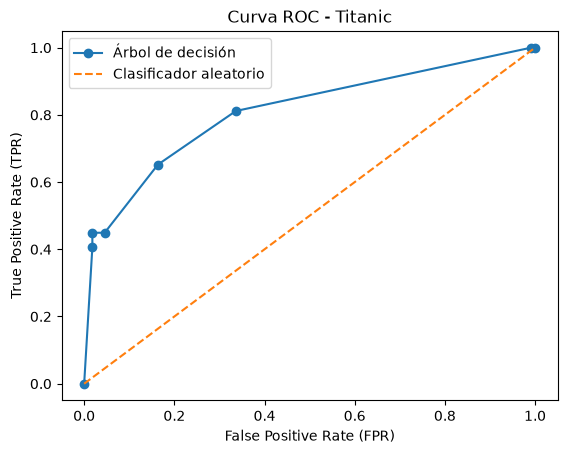

In [168]:
import matplotlib.pyplot as plt

plt.plot(fpr, tpr, marker="o", label="Árbol de decisión")
plt.plot([0, 1], [0, 1], linestyle="--", label="Clasificador aleatorio")

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("Curva ROC - Titanic")

plt.legend()
plt.show()

### Calculamos AUC

cuanto más se aproxima el AUC a 1, mejor capacidad tiene el clasificador para distinguir entre las clases.

In [169]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_test, y_prob_positiva)

print("AUC:", auc)

AUC: 0.8094202898550724


## 7. Conclusiones 

Con el mismo árbol de decisión pudimos comprobar que:
- Modificar el umbral cambia Precision, Recall, F1 y posiblemente Accuracy.
- La curva ROC muestra cómo cambian TPR y FPR a lo largo de distintos umbrales.
- AUC resume esa curva en un solo valor.
